# 第 1 章 初识随机模拟方法 —— 代码实现

对应笔记 `docs/mc/ch01.md`。六个实验：频率估计概率、蒙提霍尔、优惠券收集、蒲丰投针、方圆鱼缸（hit-or-miss）求 π、随机投点/平均值法计算定积分。

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 中文字体（Windows）与负号显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# 站点插图输出目录（换机器跑时改这里即可）
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch01")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2024)   # 全章共用一个随机数流
print("numpy", np.__version__)

numpy 2.4.6


## 1.1 一个简单例子：用频率估计概率

抛均匀硬币，正面频率 $S/N$ 应稳定在 $p=0.5$。右图显示误差按 $N^{-1/2}$ 量级下降——大数定律与中心极限定理在第 2 章给出理论支撑。

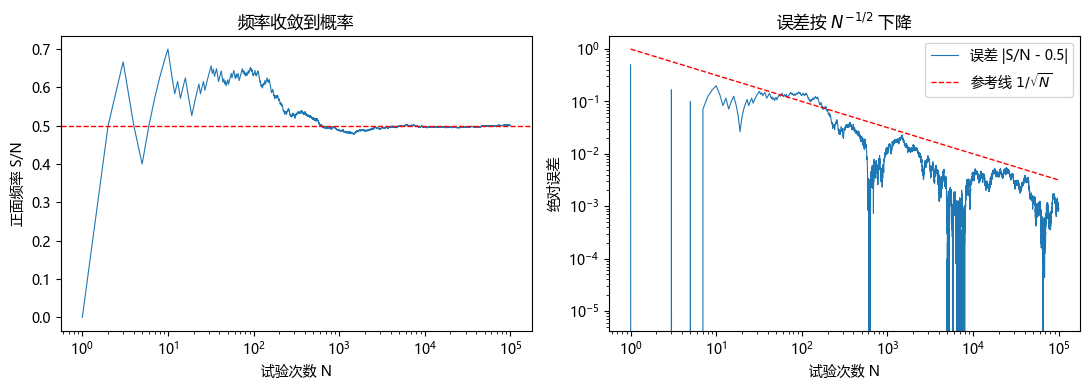

N=100 时频率 = 0.6300，N=100000 时频率 = 0.5009


In [13]:
N = 100_000
flips = rng.random(N) < 0.5          # 均匀随机数 < 0.5 记为"正面"
ns = np.arange(1, N + 1)
freq = np.cumsum(flips) / ns         # 逐步累积的频率

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ns, freq, lw=0.8)
axes[0].axhline(0.5, color="r", ls="--", lw=1)
axes[0].set_xscale("log")
axes[0].set(xlabel="试验次数 N", ylabel="正面频率 S/N", title="频率收敛到概率")
axes[1].loglog(ns, np.abs(freq - 0.5), lw=0.8, label="误差 |S/N - 0.5|")
axes[1].loglog(ns, 1 / np.sqrt(ns), "r--", lw=1, label=r"参考线 $1/\sqrt{N}$")
axes[1].set(xlabel="试验次数 N", ylabel="绝对误差", title="误差按 $N^{-1/2}$ 下降")
axes[1].legend()
fig.tight_layout(); save(fig, "out-coin.png"); plt.show()

print(f"N=100 时频率 = {freq[99]:.4f}，N=100000 时频率 = {freq[-1]:.4f}")

## 1.2 蒙提霍尔问题：换，还是不换？

三扇门后一扇是汽车、两扇是山羊。选手选门后，主持人从剩下两扇中打开一扇有山羊的门，再问换不换。直觉常说"换不换一样"，模拟说：换，胜率翻倍。

不换：胜率 ≈ 0.3337（理论 1/3 = 0.3333）
换  ：胜率 ≈ 0.6677（理论 2/3 = 0.6667）


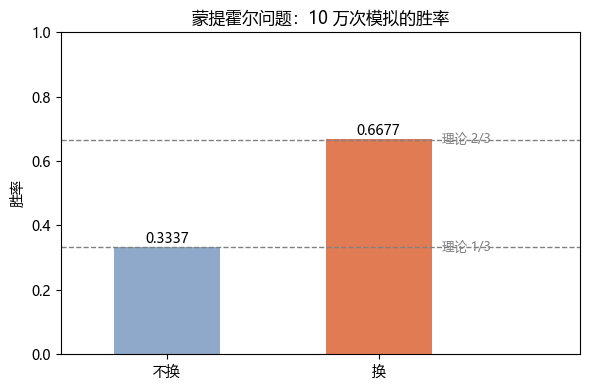

In [14]:
def monty_hall(switch, trials=100_000):
    car = rng.integers(0, 3, trials)          # 汽车所在门
    pick = rng.integers(0, 3, trials)         # 选手初始选择
    opened = (pick + rng.integers(1, 3, trials)) % 3   # 从另外两扇里随机开一扇
    opened = np.where(opened == car, 3 - pick - opened, opened)  # 误开到汽车则改开另一扇（必是山羊）
    final = np.where(switch, 3 - pick - opened, pick)
    return float(np.mean(final == car))

stay, swap = monty_hall(False), monty_hall(True)
print(f"不换：胜率 ≈ {stay:.4f}（理论 1/3 = {1/3:.4f}）")
print(f"换  ：胜率 ≈ {swap:.4f}（理论 2/3 = {2/3:.4f}）")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["不换", "换"], [stay, swap], width=0.5, color=["#8ea9c9", "#e07b54"])
ax.bar_label(bars, fmt="%.4f")
ax.axhline(1/3, color="gray", ls="--", lw=1)
ax.axhline(2/3, color="gray", ls="--", lw=1)
ax.text(1.30, 1/3, "理论 1/3", color="gray", fontsize=9, va="center")
ax.text(1.30, 2/3, "理论 2/3", color="gray", fontsize=9, va="center")
ax.set_xlim(-0.5, 1.95); ax.set_ylim(0, 1)
ax.set(ylabel="胜率", title="蒙提霍尔问题：10 万次模拟的胜率")
fig.tight_layout(); save(fig, "out-monty.png"); plt.show()

## 1.3 商品优惠券问题

每包零食随机附赠 $n$ 种优惠券之一，集齐全部 $n$ 种平均要买多少包？理论值 $E = n\,H_n = n\left(1+\frac12+\cdots+\frac1n\right)$（推导见笔记 1.3 节拓展框）。

集齐 10 种：模拟均值 = 29.35，理论 n·H_n = 29.29


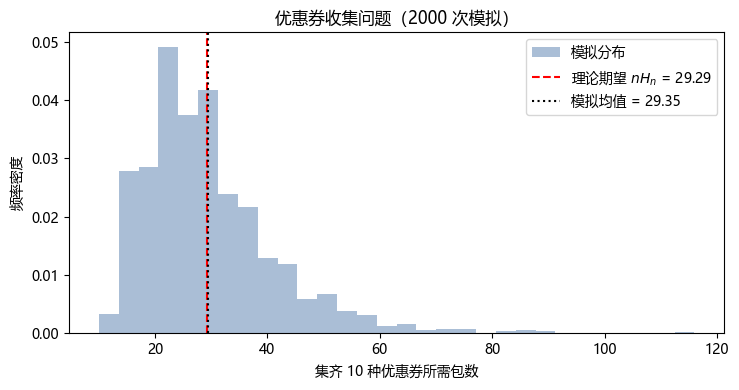

In [15]:
n, trials = 10, 2000
counts = np.empty(trials, dtype=int)
for t in range(trials):
    seen, d = set(), 0
    while len(seen) < n:
        seen.add(int(rng.integers(n)))
        d += 1
    counts[t] = d

E = n * float(np.sum(1 / np.arange(1, n + 1)))   # n·H_n
print(f"集齐 {n} 种：模拟均值 = {counts.mean():.2f}，理论 n·H_n = {E:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(counts, bins=30, density=True, alpha=0.75, color="#8ea9c9", label="模拟分布")
ax.axvline(E, color="r", ls="--", lw=1.5, label=f"理论期望 $nH_n$ = {E:.2f}")
ax.axvline(counts.mean(), color="k", ls=":", lw=1.5, label=f"模拟均值 = {counts.mean():.2f}")
ax.set(xlabel=f"集齐 {n} 种优惠券所需包数", ylabel="频率密度", title="优惠券收集问题（2000 次模拟）")
ax.legend()
fig.tight_layout(); save(fig, "out-coupon.png"); plt.show()

## 1.4 蒲丰投针求圆周率

间距 $D$ 的平行线组，随机投长 $L\le D$ 的针，相交概率 $P_{cut}=\dfrac{2L}{\pi D}$（推导见笔记 1.4 节），于是 $\hat\pi = 2L/(\hat P_{cut} D)$。

模拟判据：针中点到最近横线的距离 $d\sim U(0, D/2)$，针与线的夹角 $\theta\sim U(0, \pi/2)$（对称性），相交 $\Leftrightarrow d\le\frac{L}{2}\sin\theta$。

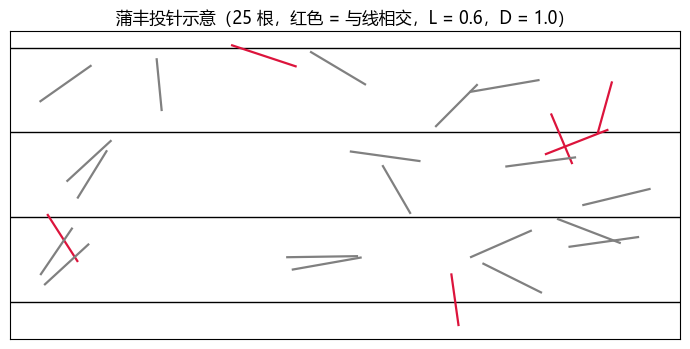

In [16]:
L, D = 0.6, 1.0
M = 25
xc, yc = rng.uniform(0, 5, M), rng.uniform(0, 3, M)
th = rng.uniform(0, np.pi, M)
dx, dy = L / 2 * np.cos(th), L / 2 * np.sin(th)
y1, y2 = yc + dy, yc - dy
cut = np.floor(y1 / D) != np.floor(y2 / D)

fig, ax = plt.subplots(figsize=(7, 3.6))
for gy in range(4):
    ax.axhline(gy * D, color="k", lw=1)
for i in range(M):
    ax.plot([xc[i] - dx[i], xc[i] + dx[i]], [y1[i], y2[i]],
            color="crimson" if cut[i] else "gray", lw=1.6)
ax.set(title=f"蒲丰投针示意（{M} 根，红色 = 与线相交，L = {L}，D = {D}）", xticks=[], yticks=[])
fig.tight_layout(); save(fig, "out-buffon-needles.png"); plt.show()

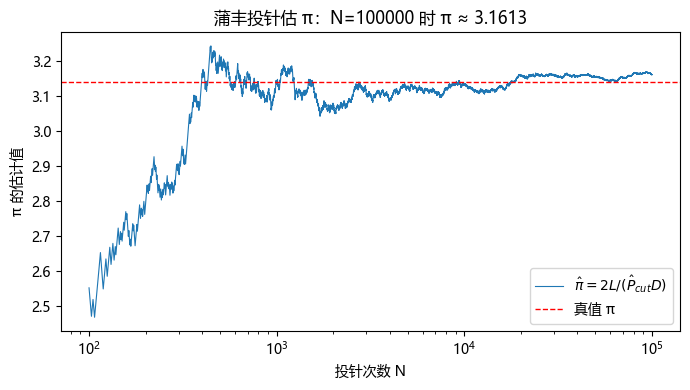

相交频率 P_cut = 0.3796（理论 0.3820），π ≈ 3.1613


In [17]:
N = 100_000
d = rng.uniform(0, D / 2, N)       # 中点到最近线的距离
th = rng.uniform(0, np.pi / 2, N)  # 针与线的夹角
hit = d <= (L / 2) * np.sin(th)
ns = np.arange(1, N + 1)
p_hat = np.cumsum(hit) / ns
with np.errstate(divide="ignore"):    # 前几步 p_hat=0，产生 nan，作图时已从 N≥100 画起
    pi_hat = 2 * L / (p_hat * D)

m = ns >= 100   # 前期分母太小，不画
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(ns[m], pi_hat[m], lw=0.8, label=r"$\hat\pi = 2L/(\hat P_{cut} D)$")
ax.axhline(np.pi, color="r", ls="--", lw=1, label="真值 π")
ax.set(xlabel="投针次数 N", ylabel="π 的估计值", title=f"蒲丰投针估 π：N={N} 时 π ≈ {pi_hat[-1]:.4f}")
ax.legend()
fig.tight_layout(); save(fig, "out-buffon.png"); plt.show()

print(f"相交频率 P_cut = {p_hat[-1]:.4f}（理论 {2*L/np.pi:.4f}），π ≈ {pi_hat[-1]:.4f}")

## 1.5 用随机模拟方法计算定积分

### 1.5.1 方圆鱼缸法求 π（hit-or-miss）

单位正方形内均匀撒点，落入四分之一圆的比例 $\times\,4$ 就是 π 的估计。

方圆鱼缸：N=4000，π ≈ 3.1140（误差 0.0276）


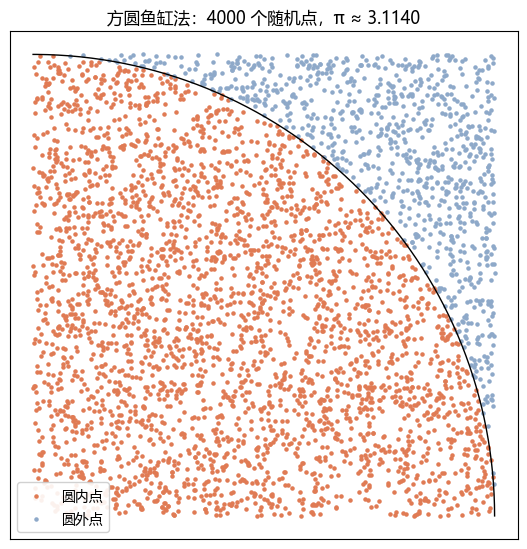

In [18]:
N = 4000
x, y = rng.random(N), rng.random(N)
inside = x**2 + y**2 <= 1
pi_hit = 4 * inside.mean()
print(f"方圆鱼缸：N={N}，π ≈ {pi_hit:.4f}（误差 {abs(pi_hit - np.pi):.4f}）")

fig, ax = plt.subplots(figsize=(5.6, 5.6))
ax.scatter(x[inside], y[inside], s=5, color="#e07b54", label="圆内点")
ax.scatter(x[~inside], y[~inside], s=5, color="#8ea9c9", label="圆外点")
t = np.linspace(0, np.pi / 2, 200)
ax.plot(np.cos(t), np.sin(t), "k-", lw=1)
ax.set(aspect="equal", xticks=[], yticks=[],
       title=f"方圆鱼缸法：{N} 个随机点，π ≈ {pi_hit:.4f}")
ax.legend(loc="lower left", framealpha=0.9)
fig.tight_layout(); save(fig, "out-hitormiss.png"); plt.show()

### 1.5.2 随机投点法与平均值法

目标 $\displaystyle I=\int_0^1 e^{-x^2}\,dx$（真值 0.7468241…）。两种做法：

- **随机投点（hit-or-miss）**：在 $[0,1]\times[0,1]$ 内撒点，落在曲线下方的比例 ≈ $I$；
- **平均值法（样本均值）**：$I\approx \frac{1}{N}\sum g(x_i)$，$x_i\sim U(0,1)$。

平均值法方差更小（第 10 章定量分析）。

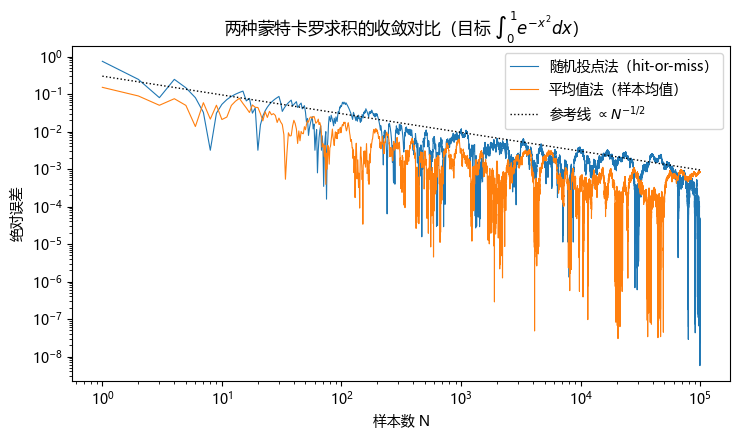

N=100000: 投点法 = 0.74684，平均值法 = 0.74764，真值 = 0.74682


In [19]:
exact = 0.7468241328124271
N = 100_000
ns = np.arange(1, N + 1)

x, y = rng.random(N), rng.random(N)
hm = np.cumsum(y <= np.exp(-x * x)) / ns          # 投点法：矩形面积 1
x2 = rng.random(N)
mean_est = np.cumsum(np.exp(-x2 * x2)) / ns       # 平均值法

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(ns, np.abs(hm - exact), lw=0.8, label="随机投点法（hit-or-miss）")
ax.loglog(ns, np.abs(mean_est - exact), lw=0.8, label="平均值法（样本均值）")
ax.loglog(ns, 0.3 / np.sqrt(ns), "k:", lw=1, label=r"参考线 $\propto N^{-1/2}$")
ax.set(xlabel="样本数 N", ylabel="绝对误差",
       title="两种蒙特卡罗求积的收敛对比（目标 $\\int_0^1 e^{-x^2}dx$）")
ax.legend()
fig.tight_layout(); save(fig, "out-quad.png"); plt.show()

print(f"N={N}: 投点法 = {hm[-1]:.5f}，平均值法 = {mean_est[-1]:.5f}，真值 = {exact:.5f}")

## 1.6 小结

- 蒙特卡罗的两类视角：把随机过程直接"演"出来（**模拟**），或把问题写成期望/积分再"抽"出来（**求积**）；
- 所有例子共享同一骨架：**建模（找分布）→ 抽样（产生一条条 history）→ 记分（统计平均）**；
- 误差 $O(N^{-1/2})$ 且与维数无关——这是蒙特卡罗对高维问题的杀手锏（第 2、10 章展开）。